# HISTORY

#### Context

* Concrete surface cracks are major defect in civil structures. Building Inspection which is done for the evaluation of rigidity and tensile strength of the building. Crack detection plays a major role in the building inspection, finding the cracks and determining the building health.

#### Content

* The datasets contains images of various concrete surfaces with and without crack. The image data are divided into two as negative (without crack) and positive (with crack) in separate folder for image classification. Each class has 20000images with a total of 40000 images with 227 x 227 pixels with RGB channels. The dataset is generated from 458 high-resolution images (4032x3024 pixel) with the method proposed by Zhang et al (2016). High resolution images found out to have high variance in terms of surface finish and illumination condition. No data augmentation in terms of random rotation or flipping or tilting is applied.

#### Acknowledgements

* This dataset is taken from the website Mendeley Data - Crack Detection, contributed by Çağlar Fırat Özgenel.

* Özgenel, Çağlar Fırat (2019), “Concrete Crack Images for Classification”, Mendeley Data, v2
http://dx.doi.org/10.17632/5y9wdsg2zt.2

#### Previous works

* 2018 – Özgenel, Ç.F., Gönenç Sorguç, A. “Performance Comparison of Pretrained Convolutional Neural Networks on Crack Detection in Buildings”, ISARC 2018, Berlin.

* Lei Zhang , Fan Yang , Yimin Daniel Zhang, and Y. J. Z., Zhang, L., Yang, F., Zhang, Y. D., & Zhu, Y. J. (2016). Road Crack Detection Using Deep Convolutional Neural Network. In 2016 IEEE International Conference on Image Processing (ICIP). http://doi.org/10.1109/ICIP.2016.7533052

# PACKAGES AND LIBRARIES

In [1]:
#GENERAL
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import random
#PATH PROCESS
import os
import os.path
from pathlib import Path
import glob
#IMAGE PROCESS
from PIL import Image
from keras.preprocessing import image
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import cv2
from keras.applications.vgg16 import preprocess_input, decode_predictions
from keras.preprocessing import image
from skimage.feature import hessian_matrix, hessian_matrix_eigvals
from scipy.ndimage.filters import convolve
from skimage import data, io, filters
import skimage
from skimage.morphology import convex_hull_image, erosion
#SCALER & TRANSFORMATION
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler
from keras.utils.np_utils import to_categorical
from sklearn.model_selection import train_test_split
from keras import regularizers
from sklearn.preprocessing import LabelEncoder
#ACCURACY CONTROL
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report, roc_auc_score, roc_curve
from sklearn.model_selection import GridSearchCV, cross_val_score
from sklearn.metrics import mean_squared_error, r2_score
#OPTIMIZER
from keras.optimizers import RMSprop,Adam,Optimizer,Optimizer, SGD
#MODEL LAYERS
from tensorflow.keras.models import Sequential
from keras.layers import Dense, Dropout, Flatten, Conv2D, MaxPool2D, BatchNormalization,MaxPooling2D,BatchNormalization,\
                        Permute, TimeDistributed, Bidirectional,GRU, SimpleRNN, LSTM, GlobalAveragePooling2D, SeparableConv2D, ZeroPadding2D, Convolution2D, ZeroPadding2D
from keras import models
from keras import layers
import tensorflow as tf
from keras.applications import VGG16,VGG19,inception_v3
from keras import backend as K
from keras.utils import plot_model
from keras.models import load_model
#SKLEARN CLASSIFIER
from xgboost import XGBClassifier, XGBRegressor
from lightgbm import LGBMClassifier, LGBMRegressor
from catboost import CatBoostClassifier, CatBoostRegressor
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.ensemble import GradientBoostingClassifier, GradientBoostingRegressor
from sklearn.ensemble import BaggingRegressor
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.linear_model import LinearRegression
from sklearn.cross_decomposition import PLSRegression
from sklearn.linear_model import Ridge
from sklearn.linear_model import RidgeCV
from sklearn.linear_model import Lasso
from sklearn.linear_model import LassoCV
from sklearn.linear_model import ElasticNet
from sklearn.linear_model import ElasticNetCV
#IGNORING WARNINGS
from warnings import filterwarnings
filterwarnings("ignore",category=DeprecationWarning)
filterwarnings("ignore", category=FutureWarning) 
filterwarnings("ignore", category=UserWarning)

# PATH,LABEL,TRANSFORMATION PROCESS

#### MAIN PATH

In [2]:
Surface_Data = Path("../input/surface-crack-detection")

#### JPG PATH

In [3]:
Surface_JPG_Path = list(Surface_Data.glob(r"*/*.jpg"))

#### JPG LABELS

In [4]:
Surface_Labels = list(map(lambda x: os.path.split(os.path.split(x)[0])[1],Surface_JPG_Path))

#### TO SERIES

In [5]:
Surface_JPG_Path_Series = pd.Series(Surface_JPG_Path,name="JPG").astype(str)
Surface_Labels_Series = pd.Series(Surface_Labels,name="CATEGORY")

#### TO DATAFRAME

In [6]:
Main_Surface_Data = pd.concat([Surface_JPG_Path_Series,Surface_Labels_Series],axis=1)

In [7]:
print(Main_Surface_Data.head(-1))

                                                     JPG  CATEGORY
0      ../input/surface-crack-detection/Negative/0845...  Negative
1      ../input/surface-crack-detection/Negative/1981...  Negative
2      ../input/surface-crack-detection/Negative/1691...  Negative
3      ../input/surface-crack-detection/Negative/0593...  Negative
4      ../input/surface-crack-detection/Negative/0612...  Negative
...                                                  ...       ...
39994  ../input/surface-crack-detection/Positive/0011...  Positive
39995  ../input/surface-crack-detection/Positive/1231...  Positive
39996  ../input/surface-crack-detection/Positive/1864...  Positive
39997  ../input/surface-crack-detection/Positive/1270...  Positive
39998  ../input/surface-crack-detection/Positive/1281...  Positive

[39999 rows x 2 columns]


#### TO SHUFFLE

In [8]:
Main_Surface_Data = Main_Surface_Data.sample(frac=1).reset_index(drop=True)

In [9]:
print(Main_Surface_Data.head(-1))

                                                     JPG  CATEGORY
0      ../input/surface-crack-detection/Positive/0874...  Positive
1      ../input/surface-crack-detection/Positive/1392...  Positive
2      ../input/surface-crack-detection/Positive/1256...  Positive
3      ../input/surface-crack-detection/Negative/1813...  Negative
4      ../input/surface-crack-detection/Negative/1868...  Negative
...                                                  ...       ...
39994  ../input/surface-crack-detection/Positive/0517...  Positive
39995  ../input/surface-crack-detection/Negative/0490...  Negative
39996  ../input/surface-crack-detection/Negative/0065...  Negative
39997  ../input/surface-crack-detection/Negative/0586...  Negative
39998  ../input/surface-crack-detection/Negative/1976...  Negative

[39999 rows x 2 columns]


# VISUALIZATION

In [10]:
plt.style.use("dark_background")

#### LABESL

In [11]:
Positive_Surface = Main_Surface_Data[Main_Surface_Data["CATEGORY"] == "Positive"]
Negative_Surface = Main_Surface_Data[Main_Surface_Data["CATEGORY"] == "Negative"]

Positive_Surface = Positive_Surface.reset_index()
Negative_Surface = Negative_Surface.reset_index()

#### VISION FUNCTION

In [12]:
def simple_vision(path):
    figure = plt.figure(figsize=(8,8))
    
    Reading_Img = cv2.imread(path)
    Reading_Img = cv2.cvtColor(Reading_Img,cv2.COLOR_BGR2RGB)
    
    plt.xlabel(Reading_Img.shape)
    plt.ylabel(Reading_Img.size)
    plt.imshow(Reading_Img)

In [13]:
def canny_vision(path):
    figure = plt.figure(figsize=(8,8))
    
    Reading_Img = cv2.imread(path)
    Reading_Img = cv2.cvtColor(Reading_Img,cv2.COLOR_BGR2RGB)
    Canny_Img = cv2.Canny(Reading_Img,90,100)
    
    plt.xlabel(Canny_Img.shape)
    plt.ylabel(Canny_Img.size)
    plt.imshow(Canny_Img)

In [14]:
def threshold_vision(path):
    figure = plt.figure(figsize=(8,8))
    
    Reading_Img = cv2.imread(path)
    Reading_Img = cv2.cvtColor(Reading_Img,cv2.COLOR_BGR2RGB)
    _,Threshold_Img = cv2.threshold(Reading_Img,130,255,cv2.THRESH_BINARY_INV)
    
    plt.xlabel(Threshold_Img.shape)
    plt.ylabel(Threshold_Img.size)
    plt.imshow(Threshold_Img)

In [15]:
def threshold_canny(path):
    figure = plt.figure(figsize=(8,8))
    
    Reading_Img = cv2.imread(path)
    Reading_Img = cv2.cvtColor(Reading_Img,cv2.COLOR_BGR2RGB)
    _,Threshold_Img = cv2.threshold(Reading_Img,130,255,cv2.THRESH_BINARY_INV)
    Canny_Img = cv2.Canny(Threshold_Img,90,100)
    
    plt.xlabel(Canny_Img.shape)
    plt.ylabel(Canny_Img.size)
    plt.imshow(Canny_Img)

#### SIMPLE VISION

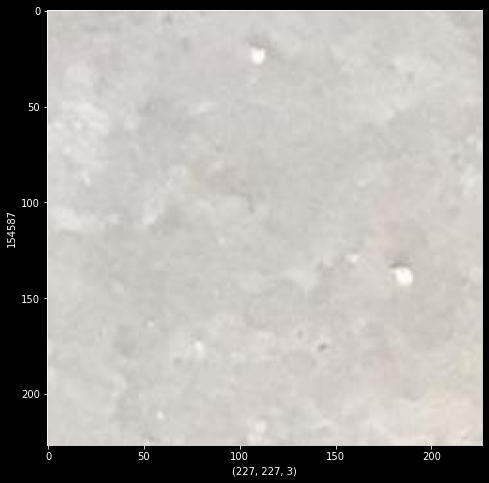

In [16]:
simple_vision(Main_Surface_Data["JPG"][4])

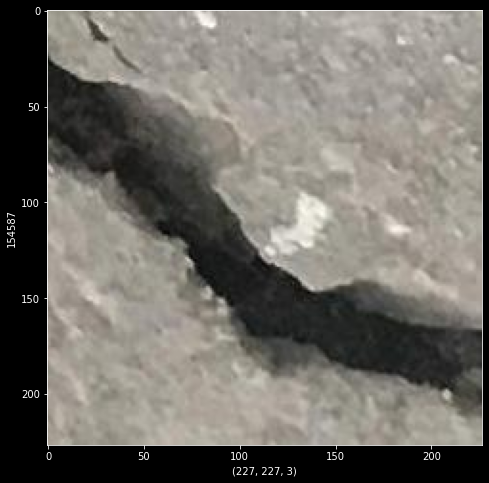

In [17]:
simple_vision(Main_Surface_Data["JPG"][2])

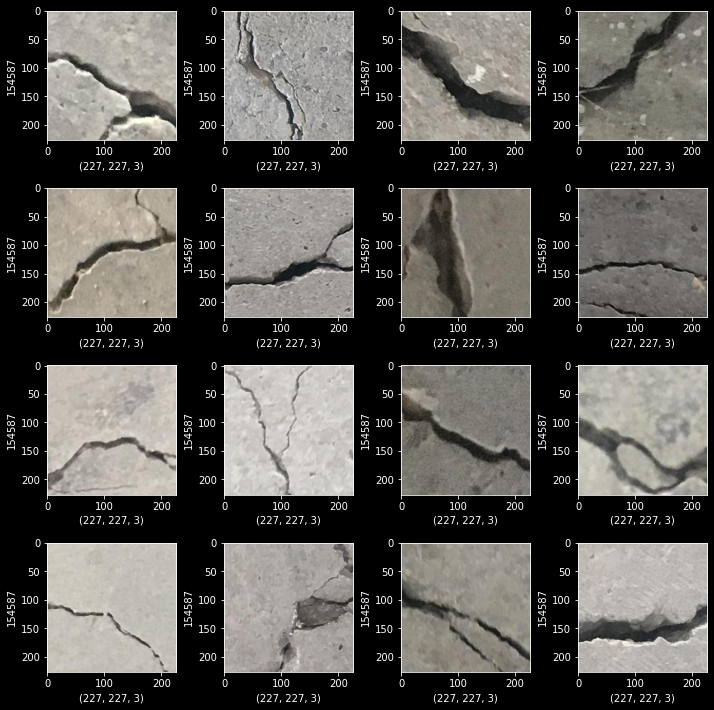

In [18]:
figure,axis = plt.subplots(4,4,figsize=(10,10))

for indexing,operations in enumerate(axis.flat):
    
    Reading_Img = cv2.imread(Positive_Surface["JPG"][indexing])
    Reading_Img = cv2.cvtColor(Reading_Img,cv2.COLOR_BGR2RGB)
    
    operations.set_xlabel(Reading_Img.shape)
    operations.set_ylabel(Reading_Img.size)
    operations.imshow(Reading_Img)
    
plt.tight_layout()
plt.show()

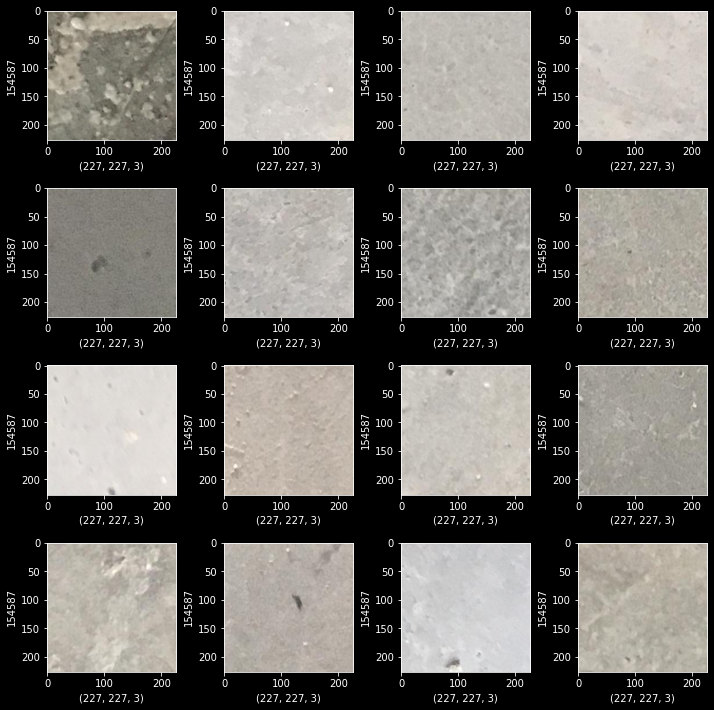

In [19]:
figure,axis = plt.subplots(4,4,figsize=(10,10))

for indexing,operations in enumerate(axis.flat):
    
    Reading_Img = cv2.imread(Negative_Surface["JPG"][indexing])
    Reading_Img = cv2.cvtColor(Reading_Img,cv2.COLOR_BGR2RGB)
    
    operations.set_xlabel(Reading_Img.shape)
    operations.set_ylabel(Reading_Img.size)
    operations.imshow(Reading_Img)
    
plt.tight_layout()
plt.show()

#### CANNY VISION

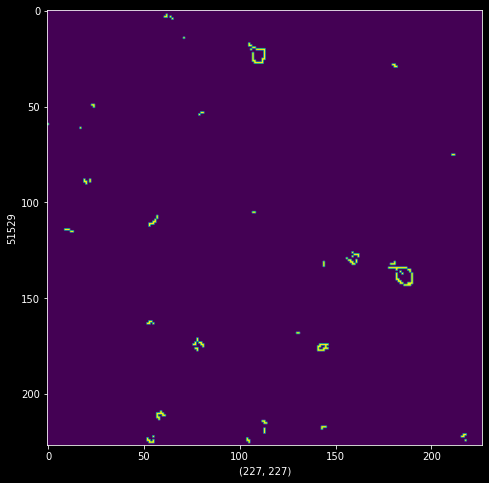

In [20]:
canny_vision(Main_Surface_Data["JPG"][4])

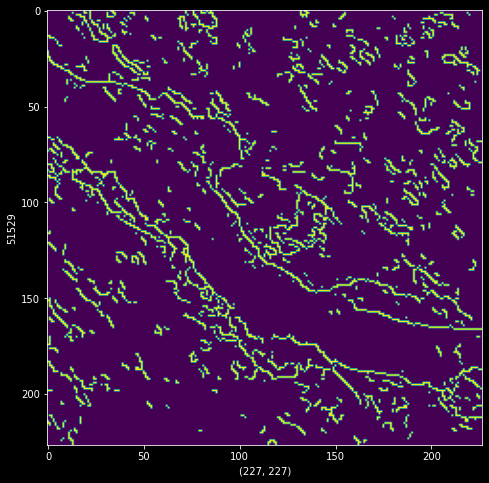

In [21]:
canny_vision(Main_Surface_Data["JPG"][2])

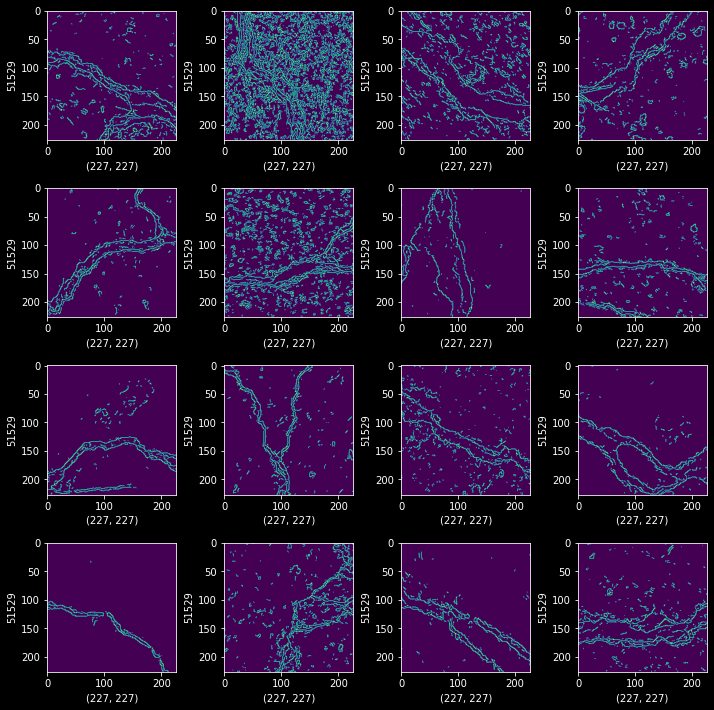

In [22]:
figure,axis = plt.subplots(4,4,figsize=(10,10))

for indexing,operations in enumerate(axis.flat):
    
    Reading_Img = cv2.imread(Positive_Surface["JPG"][indexing])
    Reading_Img = cv2.cvtColor(Reading_Img,cv2.COLOR_BGR2RGB)
    
    Canny_Img = cv2.Canny(Reading_Img,90,100)
    
    operations.set_xlabel(Canny_Img.shape)
    operations.set_ylabel(Canny_Img.size)
    operations.imshow(Canny_Img)
    
plt.tight_layout()
plt.show()

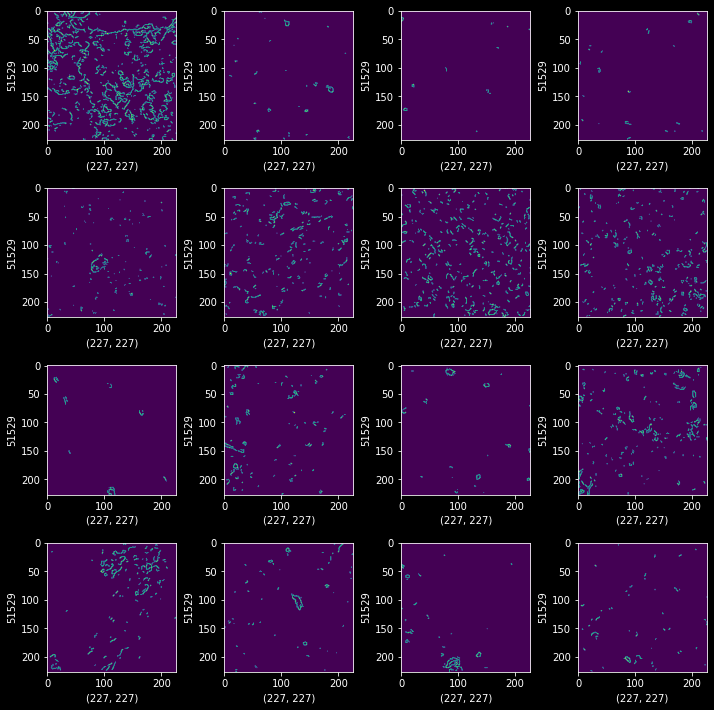

In [23]:
figure,axis = plt.subplots(4,4,figsize=(10,10))

for indexing,operations in enumerate(axis.flat):
    
    Reading_Img = cv2.imread(Negative_Surface["JPG"][indexing])
    Reading_Img = cv2.cvtColor(Reading_Img,cv2.COLOR_BGR2RGB)
    
    Canny_Img = cv2.Canny(Reading_Img,90,100)
    
    operations.set_xlabel(Canny_Img.shape)
    operations.set_ylabel(Canny_Img.size)
    operations.imshow(Canny_Img)
    
plt.tight_layout()
plt.show()

#### THRESHOLD VISION

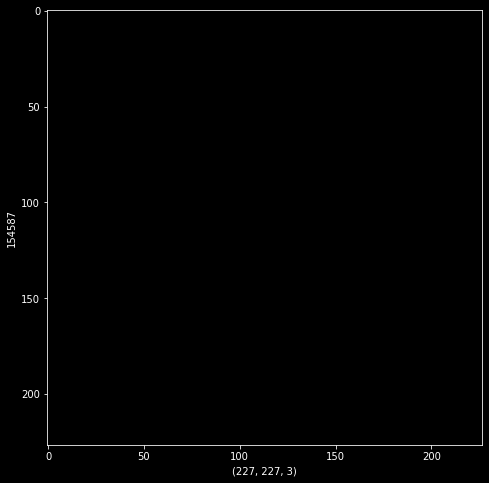

In [24]:
threshold_vision(Main_Surface_Data["JPG"][4])

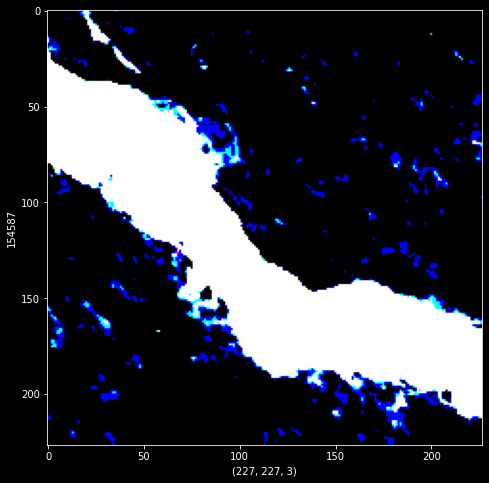

In [25]:
threshold_vision(Main_Surface_Data["JPG"][2])

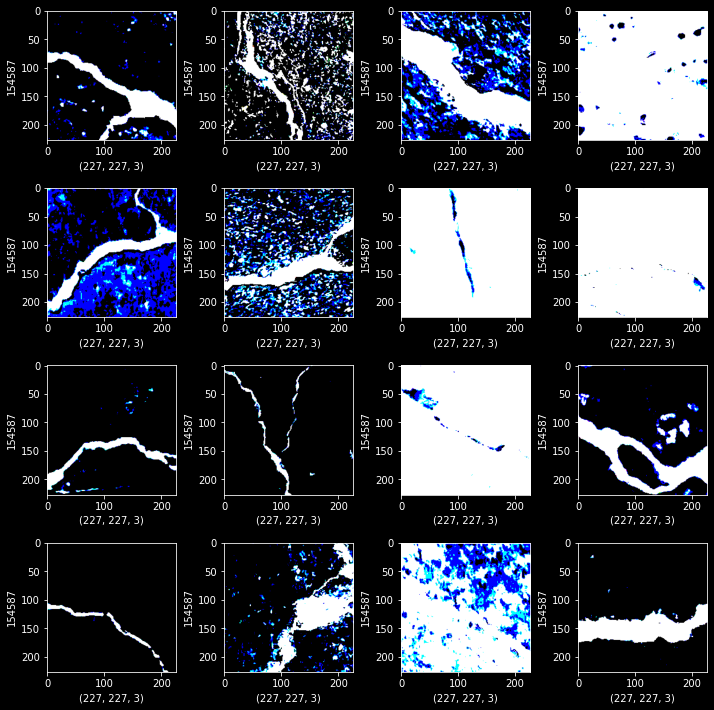

In [26]:
figure,axis = plt.subplots(4,4,figsize=(10,10))

for indexing,operations in enumerate(axis.flat):
    
    Reading_Img = cv2.imread(Positive_Surface["JPG"][indexing])
    Reading_Img = cv2.cvtColor(Reading_Img,cv2.COLOR_BGR2RGB)
    
    _,Threshold_Img = cv2.threshold(Reading_Img,150,255,cv2.THRESH_BINARY_INV)
    
    operations.set_xlabel(Threshold_Img.shape)
    operations.set_ylabel(Threshold_Img.size)
    operations.imshow(Threshold_Img)
    
plt.tight_layout()
plt.show()

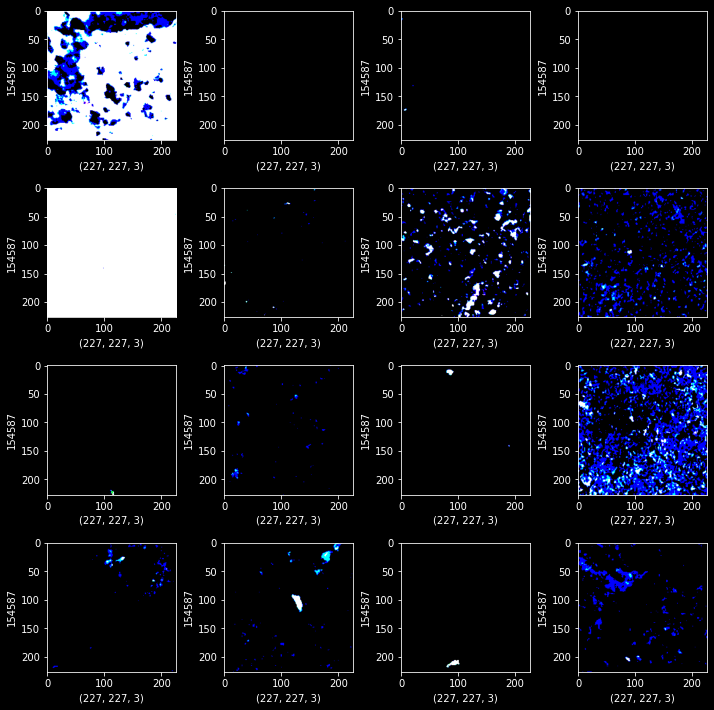

In [27]:
figure,axis = plt.subplots(4,4,figsize=(10,10))

for indexing,operations in enumerate(axis.flat):
    
    Reading_Img = cv2.imread(Negative_Surface["JPG"][indexing])
    Reading_Img = cv2.cvtColor(Reading_Img,cv2.COLOR_BGR2RGB)
    
    _,Threshold_Img = cv2.threshold(Reading_Img,150,255,cv2.THRESH_BINARY_INV)
    
    operations.set_xlabel(Threshold_Img.shape)
    operations.set_ylabel(Threshold_Img.size)
    operations.imshow(Threshold_Img)
    
plt.tight_layout()
plt.show()

#### THRESHOLD-CANNY VISION

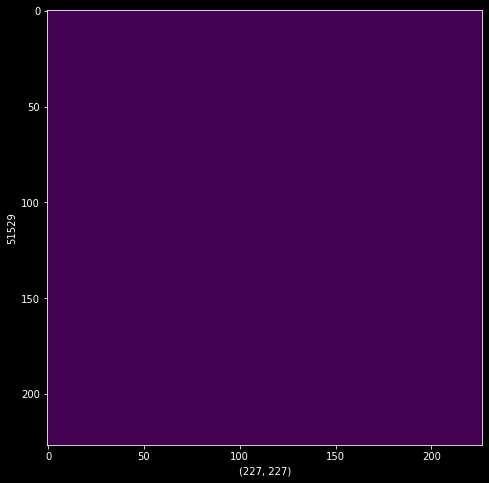

In [28]:
threshold_canny(Main_Surface_Data["JPG"][4])

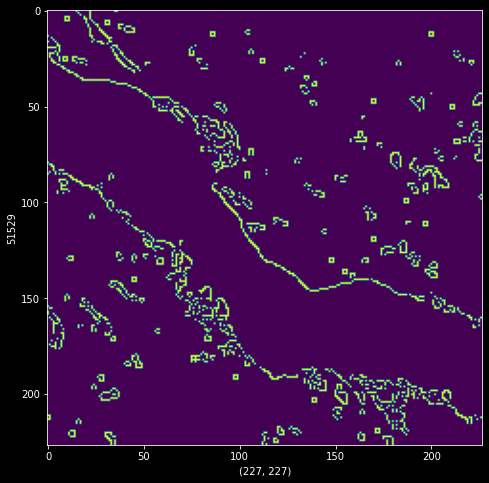

In [29]:
threshold_canny(Main_Surface_Data["JPG"][2])

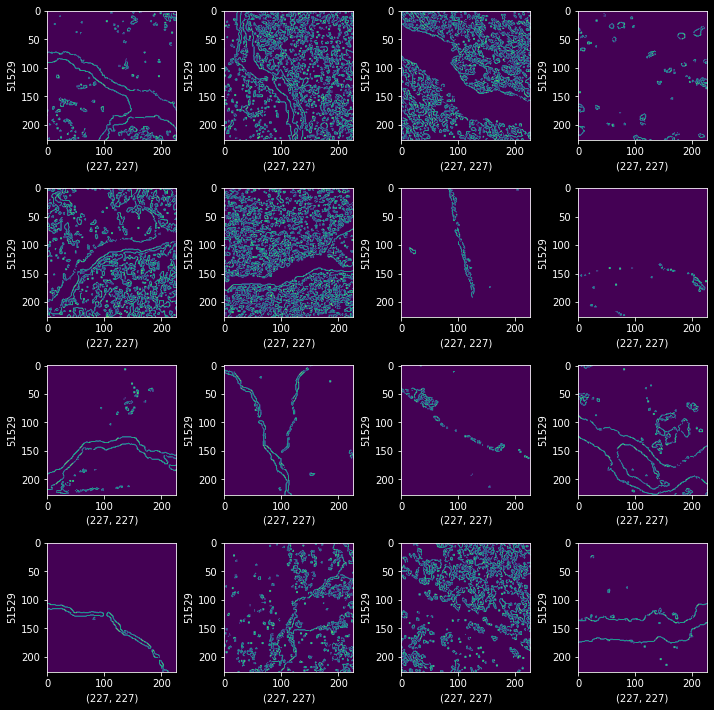

In [30]:
figure,axis = plt.subplots(4,4,figsize=(10,10))

for indexing,operations in enumerate(axis.flat):
    
    Reading_Img = cv2.imread(Positive_Surface["JPG"][indexing])
    Reading_Img = cv2.cvtColor(Reading_Img,cv2.COLOR_BGR2RGB)
    
    _,Threshold_Img = cv2.threshold(Reading_Img,150,255,cv2.THRESH_BINARY_INV)
    Canny_Img = cv2.Canny(Threshold_Img,90,100)
    
    operations.set_xlabel(Canny_Img.shape)
    operations.set_ylabel(Canny_Img.size)
    operations.imshow(Canny_Img)
    
plt.tight_layout()
plt.show()

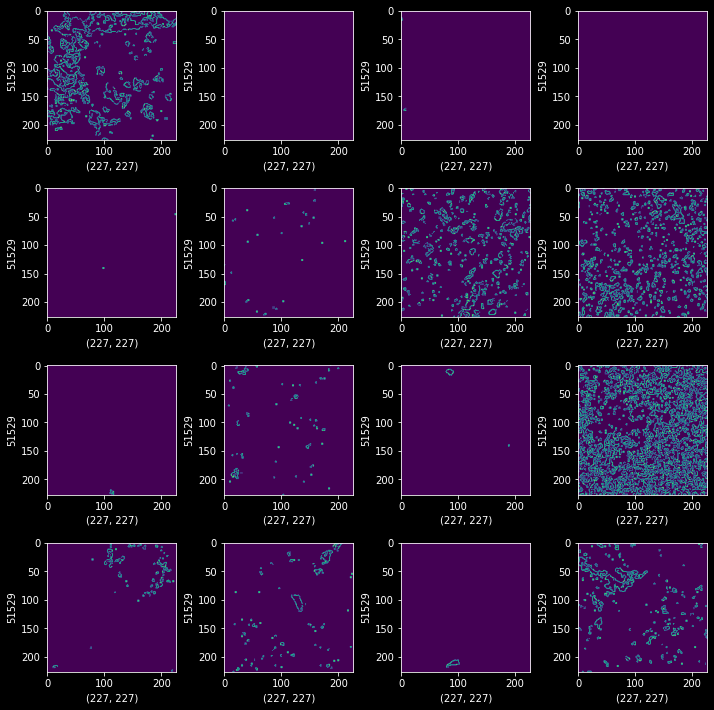

In [31]:
figure,axis = plt.subplots(4,4,figsize=(10,10))

for indexing,operations in enumerate(axis.flat):
    
    Reading_Img = cv2.imread(Negative_Surface["JPG"][indexing])
    Reading_Img = cv2.cvtColor(Reading_Img,cv2.COLOR_BGR2RGB)
    
    _,Threshold_Img = cv2.threshold(Reading_Img,150,255,cv2.THRESH_BINARY_INV)
    Canny_Img = cv2.Canny(Threshold_Img,90,100)
    
    operations.set_xlabel(Canny_Img.shape)
    operations.set_ylabel(Canny_Img.size)
    operations.imshow(Canny_Img)
    
plt.tight_layout()
plt.show()

#### DRAW CONTOURS

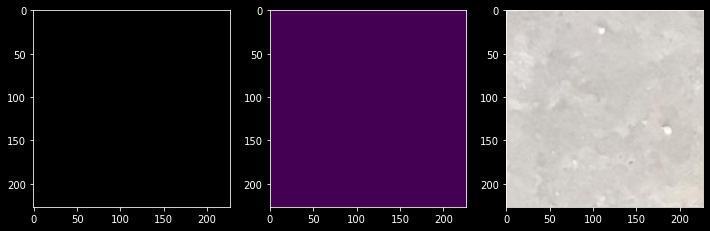

In [32]:
figure,axis = plt.subplots(nrows=1,ncols=3,figsize=(12,12))

Reading_Img = cv2.imread(Main_Surface_Data["JPG"][4])
Reading_Img = cv2.cvtColor(Reading_Img,cv2.COLOR_BGR2RGB)

_,Threshold_Img = cv2.threshold(Reading_Img,150,255,cv2.THRESH_BINARY_INV)
Canny_Img = cv2.Canny(Threshold_Img,90,100)
contours,_ = cv2.findContours(Canny_Img,cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)
Draw_Contours = cv2.drawContours(Reading_Img,contours,-1,(255,0,0),1)

axis[0].imshow(Threshold_Img)
axis[1].imshow(Canny_Img)
axis[2].imshow(Draw_Contours)

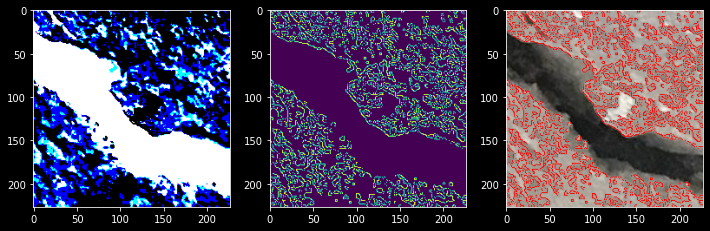

In [33]:
figure,axis = plt.subplots(nrows=1,ncols=3,figsize=(12,12))

Reading_Img = cv2.imread(Main_Surface_Data["JPG"][2])
Reading_Img = cv2.cvtColor(Reading_Img,cv2.COLOR_BGR2RGB)

_,Threshold_Img = cv2.threshold(Reading_Img,150,255,cv2.THRESH_BINARY_INV)
Canny_Img = cv2.Canny(Threshold_Img,90,100)
contours,_ = cv2.findContours(Canny_Img,cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)
Draw_Contours = cv2.drawContours(Reading_Img,contours,-1,(255,0,0),1)

axis[0].imshow(Threshold_Img)
axis[1].imshow(Canny_Img)
axis[2].imshow(Draw_Contours)

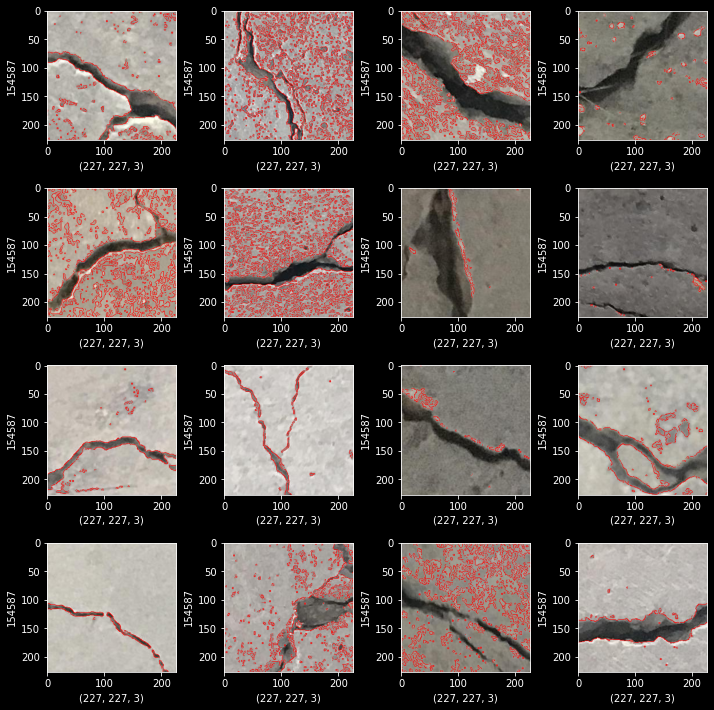

In [34]:
figure,axis = plt.subplots(4,4,figsize=(10,10))

for indexing,operations in enumerate(axis.flat):
    
    Reading_Img = cv2.imread(Positive_Surface["JPG"][indexing])
    Reading_Img = cv2.cvtColor(Reading_Img,cv2.COLOR_BGR2RGB)
    
    _,Threshold_Img = cv2.threshold(Reading_Img,150,255,cv2.THRESH_BINARY_INV)
    Canny_Img = cv2.Canny(Threshold_Img,90,100)
    contours,_ = cv2.findContours(Canny_Img,cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)
    Draw_Contours_Positive = cv2.drawContours(Reading_Img,contours,-1,(255,0,0),1)
    
    operations.set_xlabel(Draw_Contours_Positive.shape)
    operations.set_ylabel(Draw_Contours_Positive.size)
    operations.imshow(Draw_Contours_Positive)
    
plt.tight_layout()
plt.show()

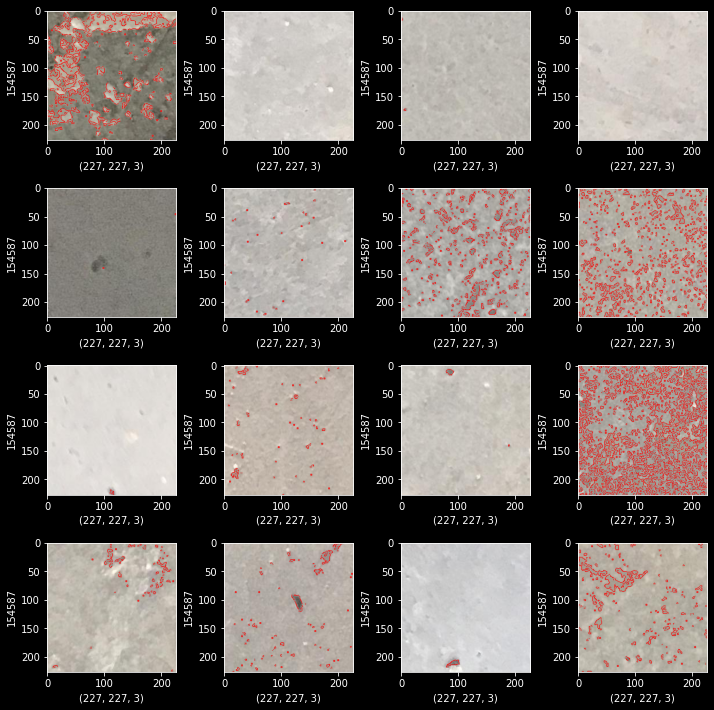

In [35]:
figure,axis = plt.subplots(4,4,figsize=(10,10))

for indexing,operations in enumerate(axis.flat):
    
    Reading_Img = cv2.imread(Negative_Surface["JPG"][indexing])
    Reading_Img = cv2.cvtColor(Reading_Img,cv2.COLOR_BGR2RGB)
    
    _,Threshold_Img = cv2.threshold(Reading_Img,150,255,cv2.THRESH_BINARY_INV)
    Canny_Img = cv2.Canny(Threshold_Img,90,100)
    contours,_ = cv2.findContours(Canny_Img,cv2.RETR_EXTERNAL,cv2.CHAIN_APPROX_SIMPLE)
    Draw_Contours_Negative = cv2.drawContours(Reading_Img,contours,-1,(255,0,0),1)
    
    operations.set_xlabel(Draw_Contours_Negative.shape)
    operations.set_ylabel(Draw_Contours_Negative.size)
    operations.imshow(Draw_Contours_Negative)
    
plt.tight_layout()
plt.show()

#### HESSIAN MATRIX

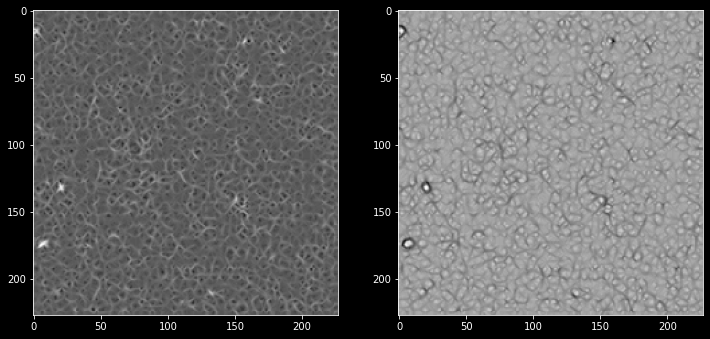

In [36]:
figure,axis = plt.subplots(nrows=1,ncols=2,figsize=(12,12))

Reading_Img = cv2.imread(Negative_Surface["JPG"][2])
Reading_Img = cv2.cvtColor(Reading_Img,cv2.COLOR_BGR2GRAY)

Hessian_Matrix_Img = hessian_matrix(Reading_Img,sigma=0.15,order="rc")
maxima_Img,minima_Img = hessian_matrix_eigvals(Hessian_Matrix_Img)

axis[0].imshow(maxima_Img,cmap="Greys_r")
axis[1].imshow(minima_Img,cmap="Greys_r")

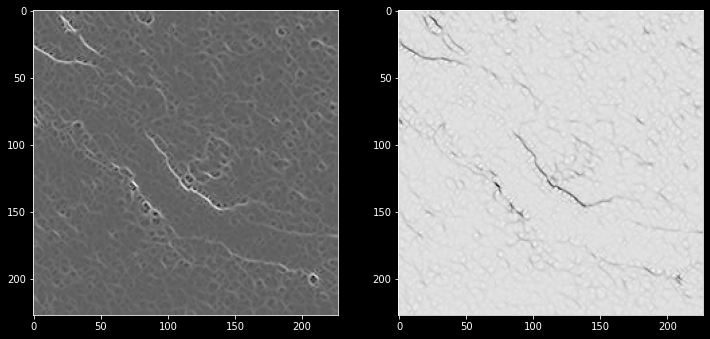

In [37]:
figure,axis = plt.subplots(nrows=1,ncols=2,figsize=(12,12))

Reading_Img = cv2.imread(Positive_Surface["JPG"][2])
Reading_Img = cv2.cvtColor(Reading_Img,cv2.COLOR_BGR2GRAY)

Hessian_Matrix_Img = hessian_matrix(Reading_Img,sigma=0.15,order="rc")
maxima_Img,minima_Img = hessian_matrix_eigvals(Hessian_Matrix_Img)

axis[0].imshow(maxima_Img,cmap="Greys_r")
axis[1].imshow(minima_Img,cmap="Greys_r")

#### THRESHOLD SKELETON MORPHOLOGY

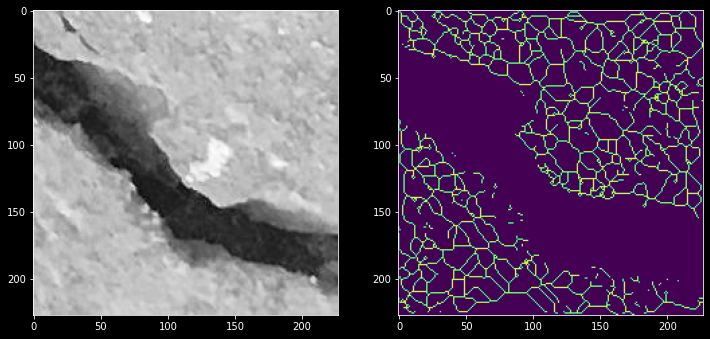

In [38]:
figure,axis = plt.subplots(nrows=1,ncols=2,figsize=(12,12))

Reading_Img = cv2.imread(Positive_Surface["JPG"][2])
Reading_Img = cv2.cvtColor(Reading_Img,cv2.COLOR_BGR2GRAY)
_,Threshold_Img = cv2.threshold(Reading_Img,150,255,cv2.THRESH_BINARY_INV)

Array_Img = np.array(Reading_Img > Threshold_Img).astype(int)
Skeleton_Morphology_Img = skimage.morphology.skeletonize(Array_Img)

axis[0].imshow(Reading_Img,cmap="Greys_r")
axis[1].imshow(Skeleton_Morphology_Img)

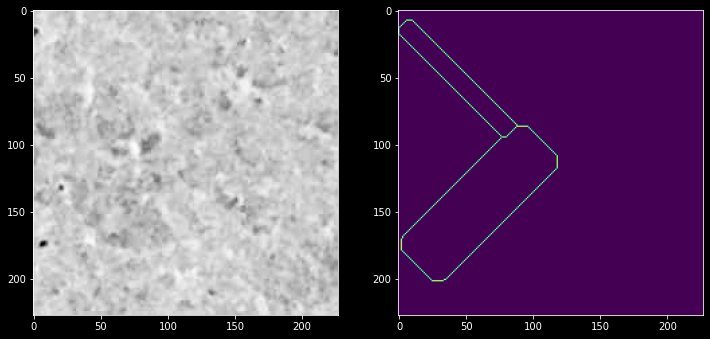

In [39]:
figure,axis = plt.subplots(nrows=1,ncols=2,figsize=(12,12))

Reading_Img = cv2.imread(Negative_Surface["JPG"][2])
Reading_Img = cv2.cvtColor(Reading_Img,cv2.COLOR_BGR2GRAY)
_,Threshold_Img = cv2.threshold(Reading_Img,150,255,cv2.THRESH_BINARY_INV)

Array_Img = np.array(Reading_Img > Threshold_Img).astype(int)
Skeleton_Morphology_Img = skimage.morphology.skeletonize(Array_Img)

axis[0].imshow(Reading_Img,cmap="Greys_r")
axis[1].imshow(Skeleton_Morphology_Img)

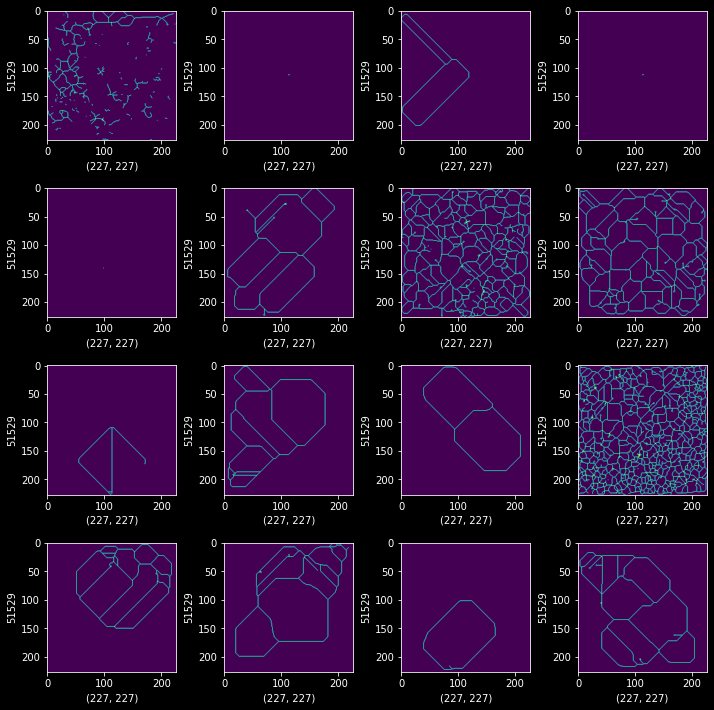

In [40]:
figure,axis = plt.subplots(4,4,figsize=(10,10))

for indexing,operations in enumerate(axis.flat):
    
    Reading_Img = cv2.imread(Negative_Surface["JPG"][indexing])
    Reading_Img = cv2.cvtColor(Reading_Img,cv2.COLOR_BGR2GRAY)
    
    _,Threshold_Img = cv2.threshold(Reading_Img,150,255,cv2.THRESH_BINARY_INV)
    Array_Img = np.array(Reading_Img > Threshold_Img).astype(int)
    Skeleton_Morphology_Img = skimage.morphology.skeletonize(Array_Img)
    
    operations.set_xlabel(Skeleton_Morphology_Img.shape)
    operations.set_ylabel(Skeleton_Morphology_Img.size)
    operations.imshow(Skeleton_Morphology_Img)
    
plt.tight_layout()
plt.show()

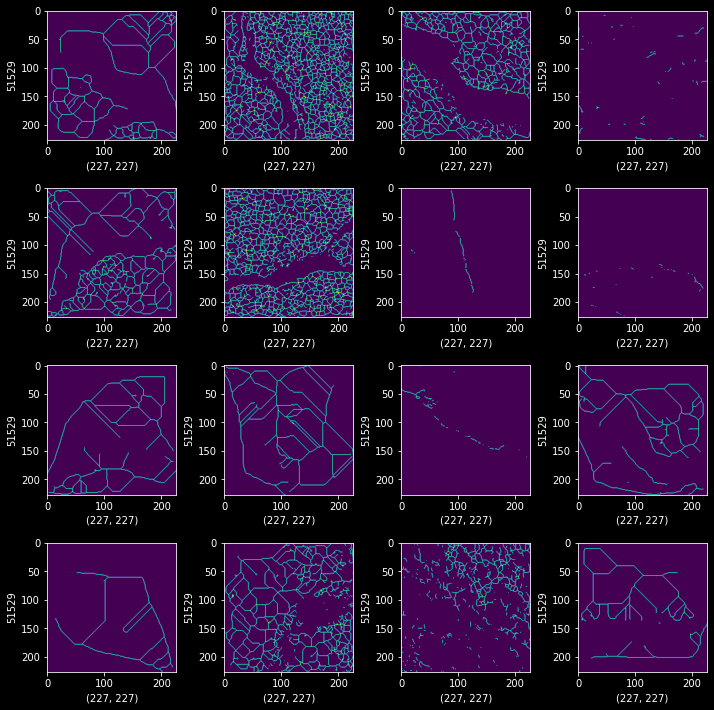

In [41]:
figure,axis = plt.subplots(4,4,figsize=(10,10))

for indexing,operations in enumerate(axis.flat):
    
    Reading_Img = cv2.imread(Positive_Surface["JPG"][indexing])
    Reading_Img = cv2.cvtColor(Reading_Img,cv2.COLOR_BGR2GRAY)
    
    _,Threshold_Img = cv2.threshold(Reading_Img,150,255,cv2.THRESH_BINARY_INV)
    Array_Img = np.array(Reading_Img > Threshold_Img).astype(int)
    Skeleton_Morphology_Img = skimage.morphology.skeletonize(Array_Img)
    
    operations.set_xlabel(Skeleton_Morphology_Img.shape)
    operations.set_ylabel(Skeleton_Morphology_Img.size)
    operations.imshow(Skeleton_Morphology_Img)
    
plt.tight_layout()
plt.show()

#### CANNY SKELETON MORPHOLOGY

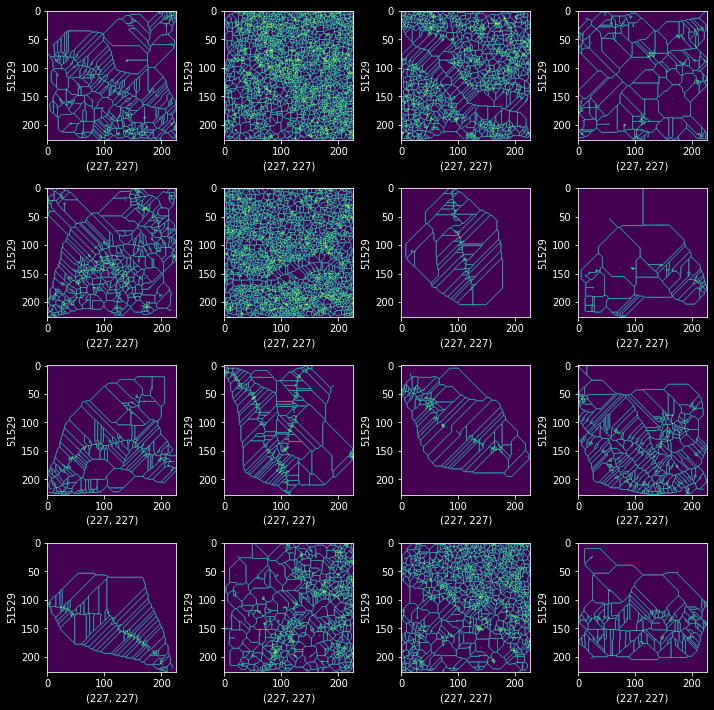

In [42]:
figure,axis = plt.subplots(4,4,figsize=(10,10))

for indexing,operations in enumerate(axis.flat):
    
    Reading_Img = cv2.imread(Positive_Surface["JPG"][indexing])
    Reading_Img = cv2.cvtColor(Reading_Img,cv2.COLOR_BGR2GRAY)
    
    _,Threshold_Img = cv2.threshold(Reading_Img,150,255,cv2.THRESH_BINARY_INV)
    Canny_Img = cv2.Canny(Threshold_Img,90,100)
    Array_Img = np.array(Reading_Img > Canny_Img).astype(int)
    Skeleton_Morphology_Img = skimage.morphology.skeletonize(Array_Img)
    
    operations.set_xlabel(Skeleton_Morphology_Img.shape)
    operations.set_ylabel(Skeleton_Morphology_Img.size)
    operations.imshow(Skeleton_Morphology_Img)
    
plt.tight_layout()
plt.show()

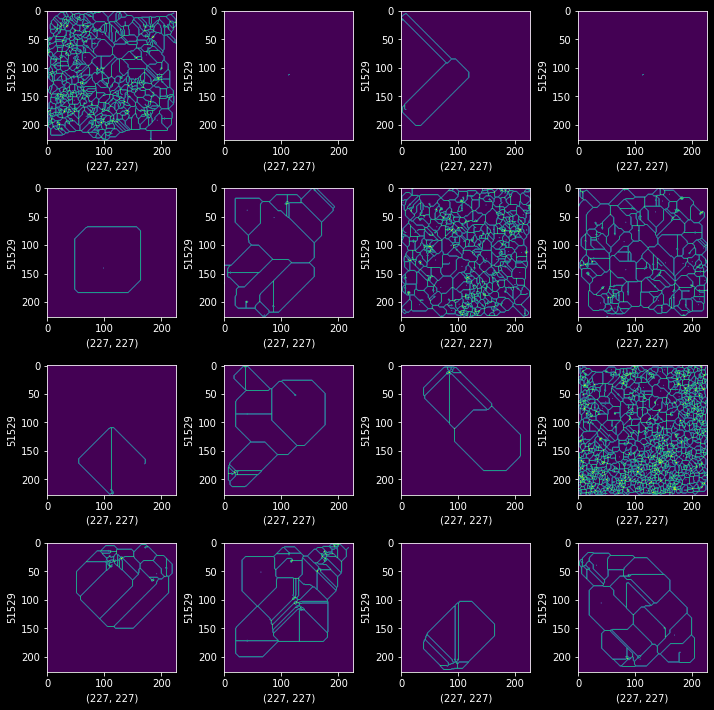

In [43]:
figure,axis = plt.subplots(4,4,figsize=(10,10))

for indexing,operations in enumerate(axis.flat):
    
    Reading_Img = cv2.imread(Negative_Surface["JPG"][indexing])
    Reading_Img = cv2.cvtColor(Reading_Img,cv2.COLOR_BGR2GRAY)
    
    _,Threshold_Img = cv2.threshold(Reading_Img,150,255,cv2.THRESH_BINARY_INV)
    Canny_Img = cv2.Canny(Threshold_Img,90,100)
    Array_Img = np.array(Reading_Img > Canny_Img).astype(int)
    Skeleton_Morphology_Img = skimage.morphology.skeletonize(Array_Img)
    
    operations.set_xlabel(Skeleton_Morphology_Img.shape)
    operations.set_ylabel(Skeleton_Morphology_Img.size)
    operations.imshow(Skeleton_Morphology_Img)
    
plt.tight_layout()
plt.show()

# SPLITTING TRAIN AND TEST

In [44]:
xTrain,xTest = train_test_split(Main_Surface_Data,train_size=0.9,shuffle=True,random_state=42)

In [45]:
print(xTrain.shape)
print(xTest.shape)

(36000, 2)
(4000, 2)


# IMAGE GENERATOR

#### STRUCTURE

In [46]:
Train_IMG_Generator = ImageDataGenerator(rescale=1./255,
                                        rotation_range=25,
                                        shear_range=0.5,
                                        zoom_range=0.5,
                                        width_shift_range=0.2,
                                        height_shift_range=0.2,
                                        brightness_range=[0.6,0.9],
                                        vertical_flip=True,
                                        validation_split=0.1)

In [47]:
Test_IMG_Generator = ImageDataGenerator(rescale=1./255)

#### HOW TO LOOK BY GENERATOR

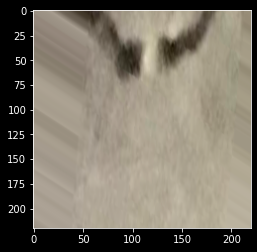

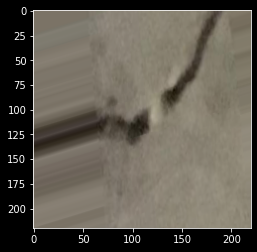

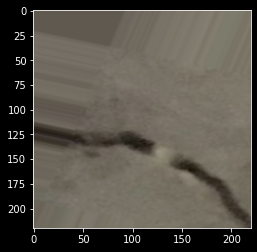

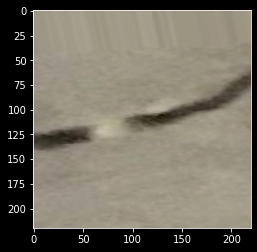

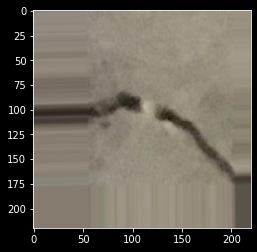

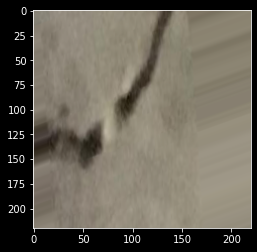

In [48]:
Example_Surface_Img = Main_Surface_Data["JPG"][444]
Loading_Img = image.load_img(Example_Surface_Img,target_size=(220,220))
Array_Img = image.img_to_array(Loading_Img)
Array_Img = Array_Img.reshape((1,) + Array_Img.shape)

i = 0

for batch in Train_IMG_Generator.flow(Array_Img,batch_size=32):
    plt.figure(i)
    Image_Out = plt.imshow(image.img_to_array(batch[0]))
    i += 1
    
    if i % 6 == 0:
        break

plt.show()

#### APPLYING

In [49]:
Train_Set = Train_IMG_Generator.flow_from_dataframe(dataframe=xTrain,
                                                   x_col="JPG",
                                                   y_col="CATEGORY",
                                                   color_mode="rgb",
                                                   class_mode="binary",
                                                   target_size=(200,200),
                                                   subset="training",
                                                    batch_size=32,
                                                    seed=32)

Found 32400 validated image filenames belonging to 2 classes.


In [50]:
Validation_Set = Train_IMG_Generator.flow_from_dataframe(dataframe=xTrain,
                                                   x_col="JPG",
                                                   y_col="CATEGORY",
                                                   color_mode="rgb",
                                                   class_mode="binary",
                                                   target_size=(200,200),
                                                   subset="validation",
                                                    batch_size=32,
                                                    seed=32)

Found 3600 validated image filenames belonging to 2 classes.


In [51]:
Test_Set = Test_IMG_Generator.flow_from_dataframe(dataframe=xTest,
                                                   x_col="JPG",
                                                   y_col="CATEGORY",
                                                   color_mode="rgb",
                                                   class_mode="binary",
                                                   target_size=(200,200),
                                                    batch_size=32,
                                                    seed=32)

Found 4000 validated image filenames belonging to 2 classes.


#### CHECKING

In [52]:
print("TRAIN: ")
print(Train_Set.class_indices)
print(Train_Set.classes[0:5])
print(Train_Set.image_shape)
print("---"*20)
print("VALIDATION: ")
print(Validation_Set.class_indices)
print(Validation_Set.classes[0:5])
print(Validation_Set.image_shape)
print("---"*20)
print("TEST: ")
print(Test_Set.class_indices)
print(Test_Set.classes[0:5])
print(Test_Set.image_shape)

TRAIN: 
{'Negative': 0, 'Positive': 1}
[1, 0, 0, 1, 0]
(200, 200, 3)
------------------------------------------------------------
VALIDATION: 
{'Negative': 0, 'Positive': 1}
[0, 1, 0, 1, 0]
(200, 200, 3)
------------------------------------------------------------
TEST: 
{'Negative': 0, 'Positive': 1}
[1, 1, 1, 1, 1]
(200, 200, 3)


# MODEL RNN-LSTM

#### PARAMETERS

In [53]:
print(Train_Set.image_shape[0],Train_Set.image_shape[1],Train_Set.image_shape[2])

200 200 3


In [54]:
compile_optimizer = "adam"
compile_loss = "binary_crossentropy"
input_dim = (Train_Set.image_shape[0],Train_Set.image_shape[1],Train_Set.image_shape[2])
class_dim = 1

#### CALLBACKS

In [55]:
Early_Stopper = tf.keras.callbacks.EarlyStopping(monitor="loss",patience=3,mode="min")
Checkpoint_Model = tf.keras.callbacks.ModelCheckpoint(monitor="val_accuracy",
                                                      save_best_only=True,
                                                      save_weights_only=True,
                                                      filepath="./modelcheck")

#### STRUCTURE

In [62]:
Model = Sequential()

Model.add(Conv2D(32,(3,3),activation="relu",input_shape=input_dim))
Model.add(BatchNormalization())
Model.add(MaxPooling2D((2,2),strides=2))

Model.add(Conv2D(64,(3,3),activation="relu",padding="same"))
Model.add(Dropout(0.3))
Model.add(MaxPooling2D((2,2),strides=2))

Model.add(Conv2D(128,(3,3),activation="relu",padding="same"))
Model.add(Dropout(0.3))
Model.add(MaxPooling2D((2,2),strides=2))

Model.add(Conv2D(256,(3,3),activation="relu",padding="same"))
Model.add(Dropout(0.3))
Model.add(MaxPooling2D((2,2),strides=2))

Model.add(Flatten())
Model.add(Dense(1024,activation="relu"))
Model.add(Dropout(0.5))
Model.add(Dense(class_dim,activation="sigmoid"))

In [63]:
Model.compile(optimizer=compile_optimizer,loss=compile_loss,metrics=["accuracy"])

In [64]:
CNN_Model = Model.fit(Train_Set,
                      validation_data=Validation_Set,
                      callbacks=[Early_Stopper,Checkpoint_Model],
                      epochs=50)

Epoch 1/50
1013/1013 [==============================] - 541s 533ms/step - loss: 0.5691 - accuracy: 0.9031 - val_loss: 0.0889 - val_accuracy: 0.9756
Epoch 2/50
1013/1013 [==============================] - 513s 506ms/step - loss: 0.0435 - accuracy: 0.9865 - val_loss: 0.0963 - val_accuracy: 0.9689
Epoch 3/50
1013/1013 [==============================] - 517s 511ms/step - loss: 0.0473 - accuracy: 0.9858 - val_loss: 0.0741 - val_accuracy: 0.9728
Epoch 4/50
1013/1013 [==============================] - 516s 509ms/step - loss: 0.0459 - accuracy: 0.9878 - val_loss: 0.1931 - val_accuracy: 0.9175
Epoch 5/50
1013/1013 [==============================] - 516s 510ms/step - loss: 0.0424 - accuracy: 0.9869 - val_loss: 0.0871 - val_accuracy: 0.9678
Epoch 6/50
1013/1013 [==============================] - 539s 532ms/step - loss: 0.0403 - accuracy: 0.9885 - val_loss: 0.5332 - val_accuracy: 0.7581
Epoch 7/50
1013/1013 [==============================] - 542s 535ms/step - loss: 0.0367 - accuracy: 0.9893 - val_

#### CHECKING MODEL

In [65]:
print(Model.summary())

Model: "sequential_2"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
conv2d_4 (Conv2D)            (None, 198, 198, 32)      896       
_________________________________________________________________
batch_normalization_2 (Batch (None, 198, 198, 32)      128       
_________________________________________________________________
max_pooling2d_6 (MaxPooling2 (None, 99, 99, 32)        0         
_________________________________________________________________
conv2d_5 (Conv2D)            (None, 99, 99, 64)        18496     
_________________________________________________________________
dropout_6 (Dropout)          (None, 99, 99, 64)        0         
_________________________________________________________________
max_pooling2d_7 (MaxPooling2 (None, 49, 49, 64)        0         
_________________________________________________________________
conv2d_6 (Conv2D)            (None, 49, 49, 128)      

In [66]:
Model.save("Model_Last_Prediction.h5")

<AxesSubplot:>

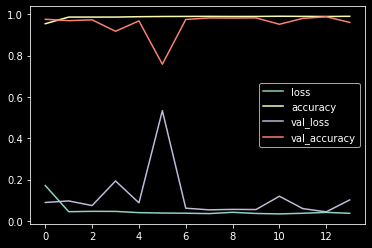

In [67]:
Grap_Data = pd.DataFrame(CNN_Model.history)
Grap_Data.plot()

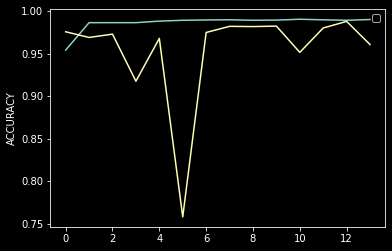

In [68]:
plt.plot(CNN_Model.history["accuracy"])
plt.plot(CNN_Model.history["val_accuracy"])
plt.ylabel("ACCURACY")
plt.legend()
plt.show()

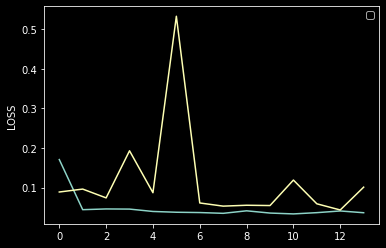

In [69]:
plt.plot(CNN_Model.history["loss"])
plt.plot(CNN_Model.history["val_loss"])
plt.ylabel("LOSS")
plt.legend()
plt.show()

#### PREDICTION PROCESS

In [70]:
Model_Results = Model.evaluate(Test_Set)
print("LOSS:  " + "%.4f" % Model_Results[0])
print("ACCURACY:  " + "%.2f" % Model_Results[1])

125/125 [==============================] - 28s 228ms/step - loss: 0.2562 - accuracy: 0.8975
LOSS:  0.2562
ACCURACY:  0.90


In [71]:
Model_Test_Prediction = Model.predict(Test_Set)
Model_Test_Prediction = Model_Test_Prediction.argmax(axis=-1)
print(Model_Test_Prediction)

[0 0 0 ... 0 0 0]


In [72]:
Model_Test_Prediction_Classes = Model.predict_classes(Test_Set)
print(Model_Test_Prediction_Classes)

[[0]
 [0]
 [0]
 ...
 [0]
 [0]
 [0]]


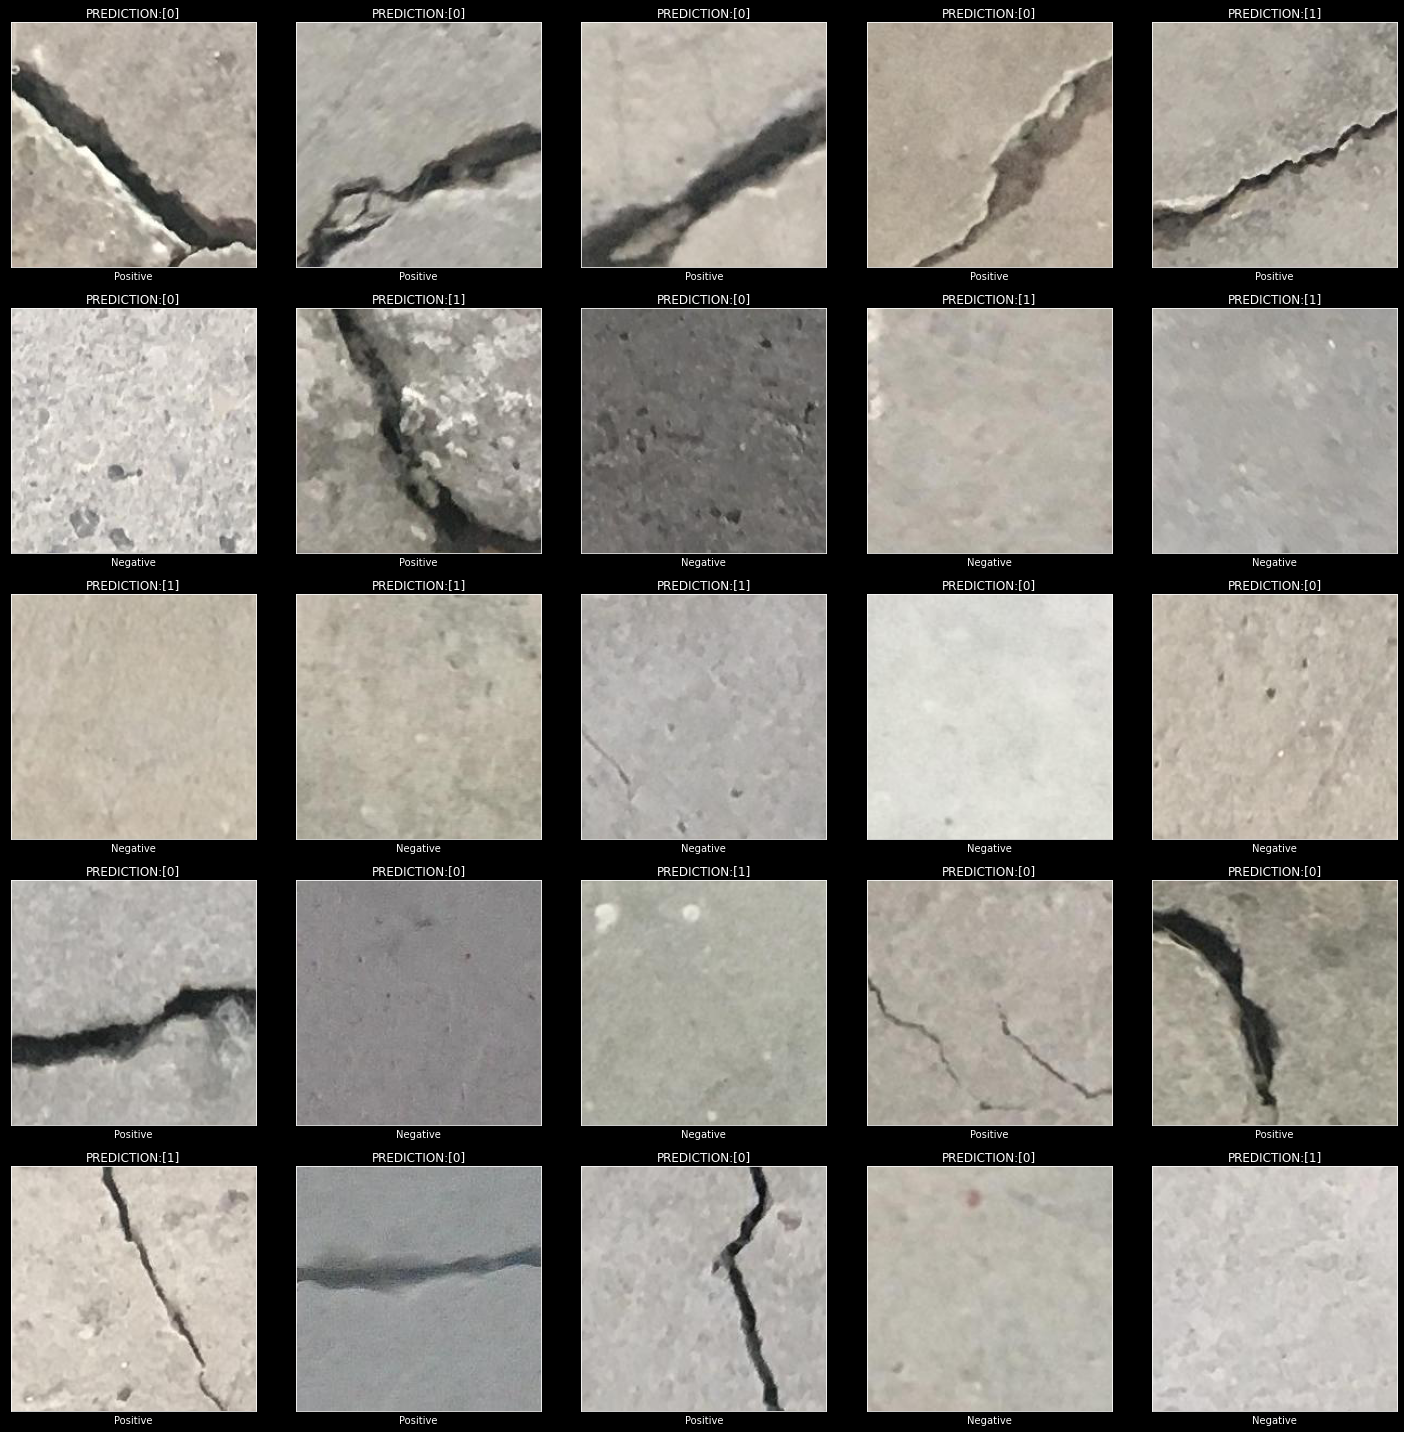

In [73]:
fig, axes = plt.subplots(nrows=5,
                         ncols=5,
                         figsize=(20, 20),
                        subplot_kw={'xticks': [], 'yticks': []})

for i, ax in enumerate(axes.flat):
    ax.imshow(plt.imread(xTest["JPG"].iloc[i]))
    ax.set_title(f"PREDICTION:{Model_Test_Prediction_Classes[i]}")
    ax.set_xlabel(xTest["CATEGORY"].iloc[i])
plt.tight_layout()
plt.show()